# Regularization in the analytical gradient-flow example

This example uses one consequential action $a\in[0,1]$ and a uniform draw $s_2\in[0,1]$. The first action earns $a$ if it survives and consumes $1-a+\varepsilon s_2$ from budget one. Thus failure occurs when $a<\varepsilon s_2$. Conditional on $a$, failure has probability $\max(0,1-a/\varepsilon)$. Subsequent raw utility and consumption are zero. The updated reserve is $(a-\varepsilon s_2)/\gamma$ with $\gamma=1/2$. In a surviving episode the reserve increases by a factor $1/\gamma$ at each subsequent step. The log barrier charges small positive reserves before the per-period reward is clipped at $-m$.

A parameter law $\mu$ on $\mathbb R$ specifies a policy through its tilt $c(\mu)=\int\varphi(x)\,\mu(dx)$. The feature is zero for $|x|\le1$ and equals $\exp[-1/(|x|-1)^2]$ outside that interval. The action density is proportional to $e^{c(\mu)a}$ on $[0,1]$. Let $V_m(\mu)$ be the policy's expected discounted clipped value and let $\Gamma$ be the reference law on parameters. The relative-entropy case in the study solves

$$
\begin{aligned}
\underset{\mu\in\mathcal P_2(\mathbb R)}{\mathrm{minimize}}\quad
   & -V_m(\mu)+\kappa\,\mathrm{KL}(\mu\Vert\Gamma),\\
\text{subject to}\quad & \mu\ll\Gamma .
\end{aligned}
$$

Here $\mathcal P_2(\mathbb R)$ is the set of probability laws with finite second moment. The constraint requires absolute continuity with respect to the Gaussian reference $\Gamma$. The objective takes value $+\infty$ when the entropy integral diverges. The study also computes population trajectories for power divergences.

[Manuscript studies and figure sources](README.md) · [Roles of regularization in training](../../docs/under-the-hood/decisions-and-theory.md#5-choose-regularizers-for-their-role)

In [1]:
from IPython.display import Image, display
import numpy as np

from barrierpg.examples.plateau import PlateauModel, chi, chi_prime

model = PlateauModel(eps=0.2, beta=0.9, gamma=0.5, m=1.0)
tilts = (0.0, 0.5, 1.0)
print(f"{'tilt':>5s} {'clipped value':>15s} {'geometric risk':>16s}")
for c in tilts:
    stats = model.stats(c)
    assert abs(stats["identity_residual"]) < 1e-10
    print(f"{c:5.2f} {stats['V_m']:15.4f} {stats['q_beta']:16.4f}")
assert np.isclose(model.stats(0.0)["q_beta"], model.eps / 2)

 tilt   clipped value   geometric risk
 0.00         -2.2533           0.1000
 0.50         -1.9319           0.0797
 1.00         -1.6382           0.0623


The value calculation integrates the policy density, the uniform draw and the barrier deductions over time. With a uniform action, integrating the conditional probability of failure from zero to $\varepsilon$ gives $\varepsilon/2$. Tilt one is the limit of the represented policies and is included to show the endpoint of the value curve.

## The model, the flow and the role of the prior

The setup figure shows the conditional failure probability, feature and action densities. The initial parameter law is supported on the flat part of the feature. A parameter there has zero first derivative and contributes no value gradient.

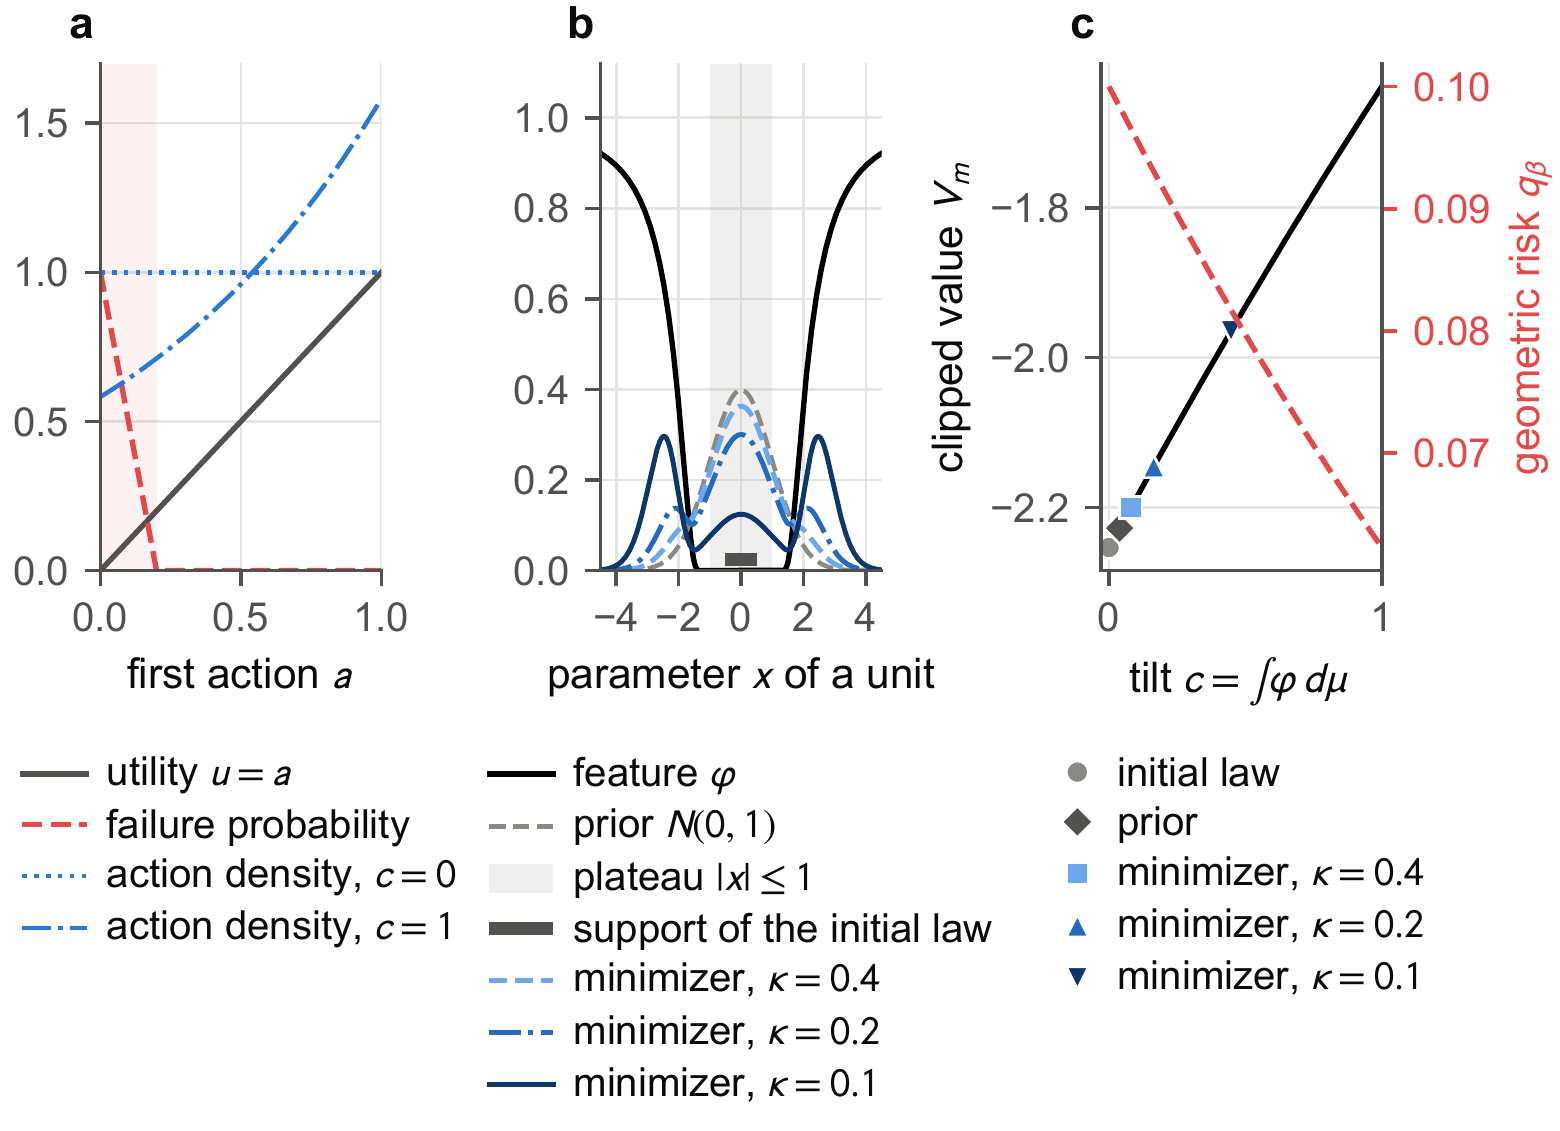

In [2]:
display(Image(filename="figures/example-setup.png", width=780))

The next figure reports the finite-volume calculations of the population gradient flow. Its left panel compares the relative objective gap with the guaranteed decay envelope at a strength above the sufficient curvature threshold. Its right panel compares the clipped value of the computed minimizers with the prior policy. A stronger pull toward the prior can improve the curvature bound and change the regularized optimum.

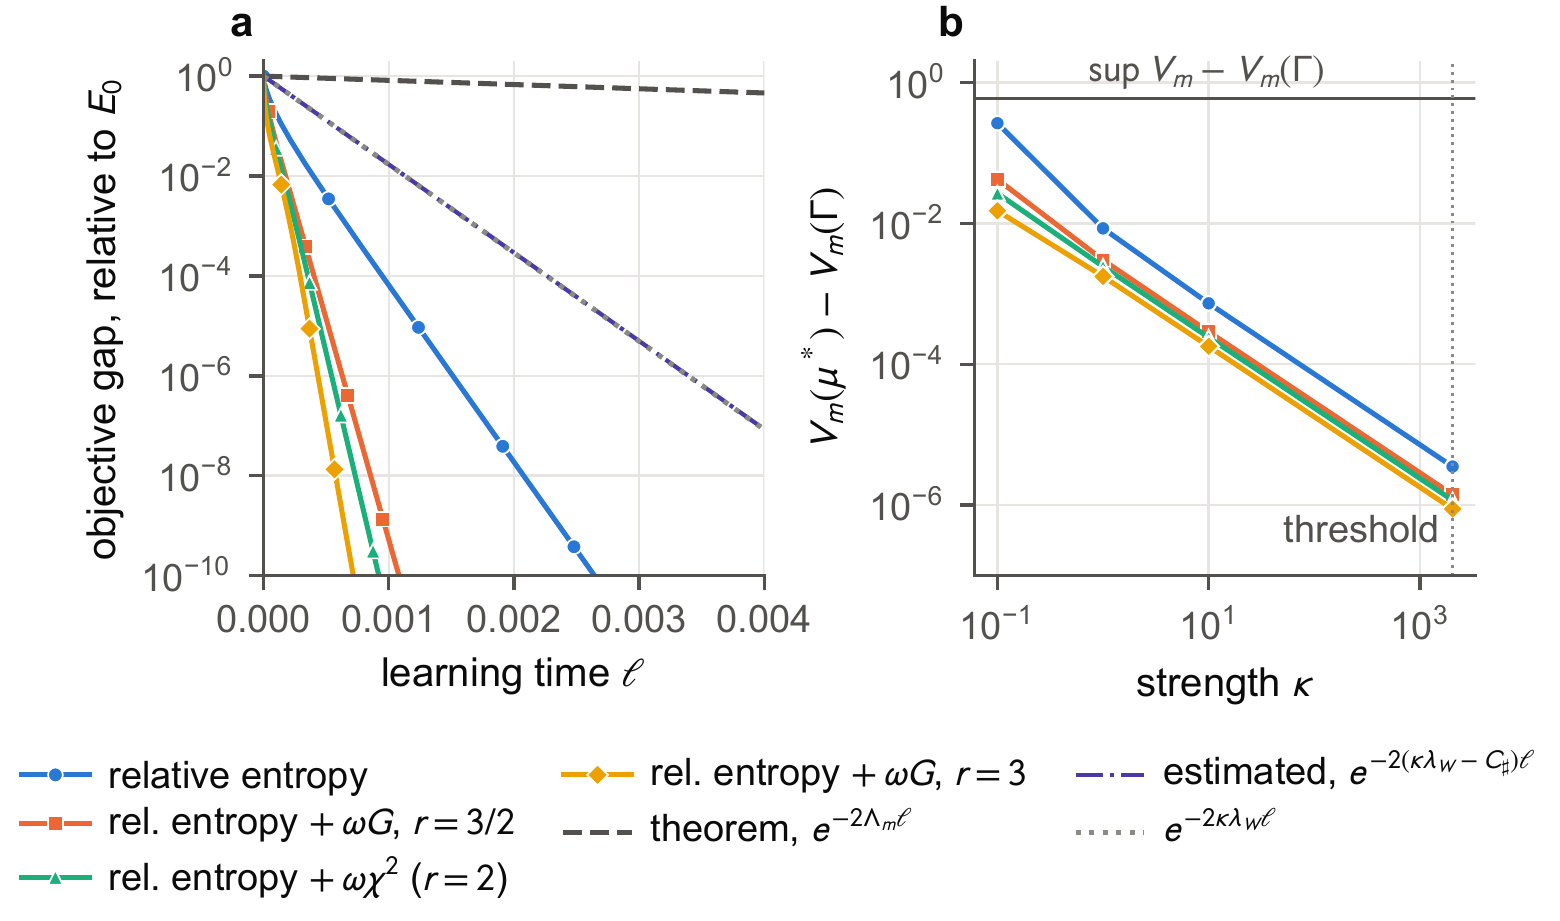

In [3]:
display(Image(filename="figures/flow-test.png", width=780))

The schedule figure compares fixed strength $0.03$ with the sequence $10$, $3$, $1$, $0.3$, $0.1$, $0.03$. Each stage lasts two units of learning time in one schedule. In the other, a stage ends when the mean clipped values in two consecutive windows of length $0.5/\kappa$ differ by less than $0.002$. The curves average eight simulations with 10,000 particles per run. The time saved depends on the prior.

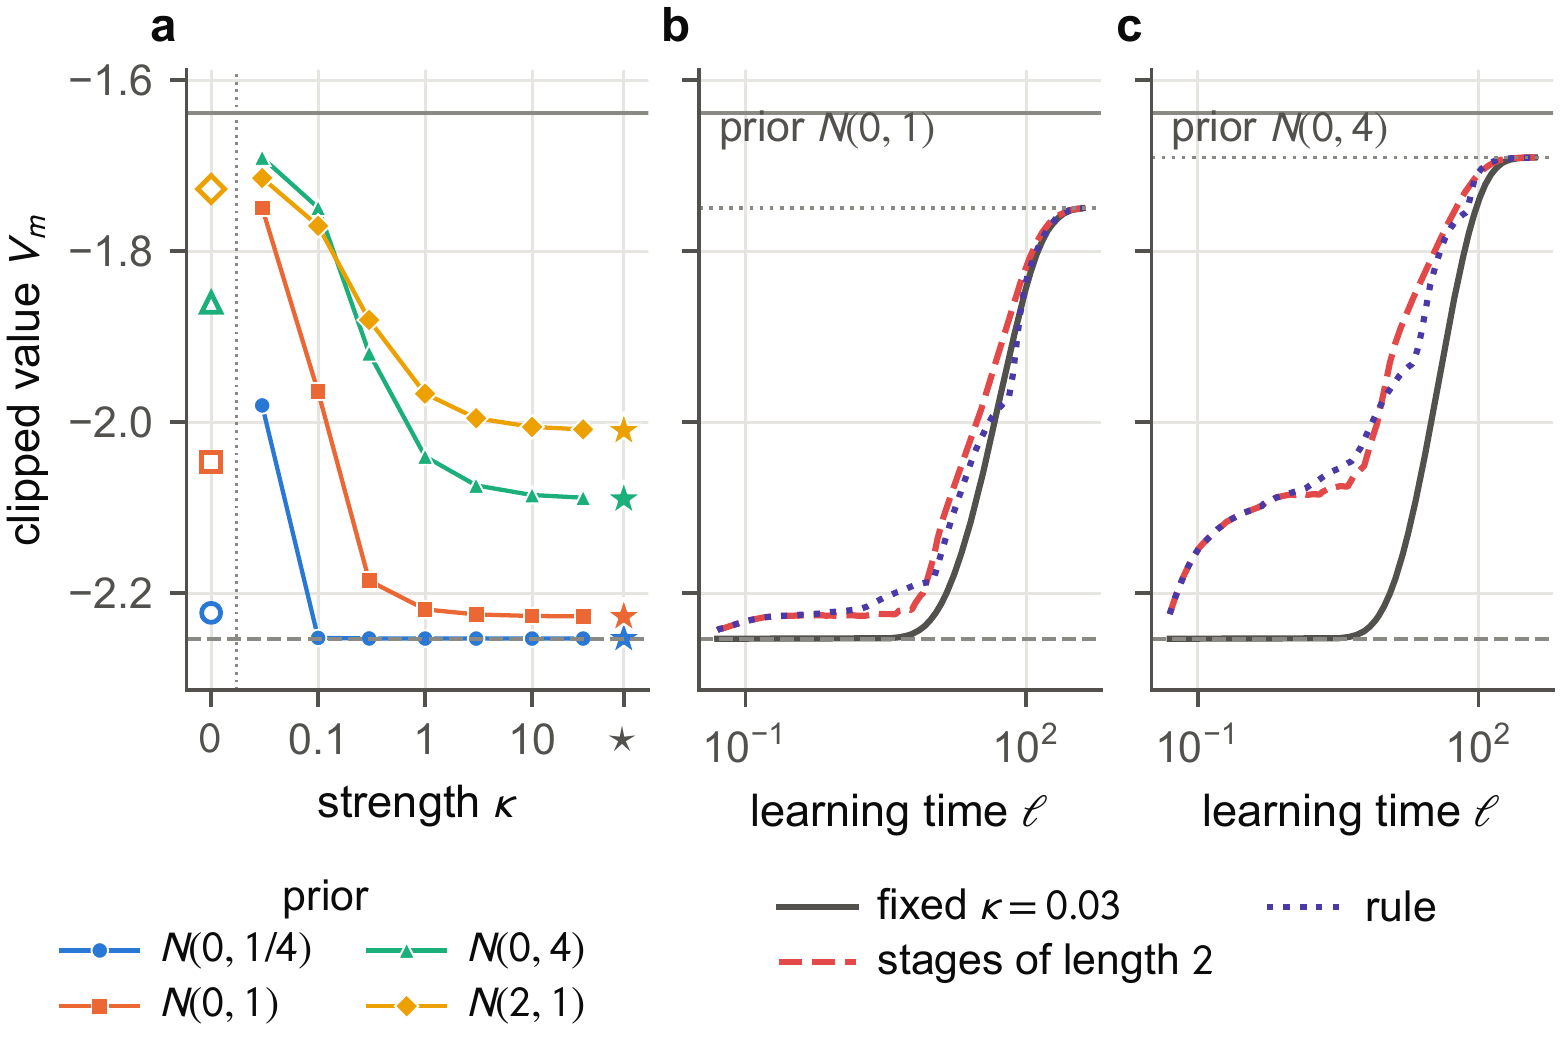

In [4]:
display(Image(filename="figures/prior-strength.png", width=780))

## Apply one discretized step

For relative entropy to $N(0,\sigma^2)$, an Euler–Maruyama step with size $h$ changes each unit by the value derivative $V_m'(c)\varphi'(x)$, an attraction $-\kappa x/\sigma^2$ and an independent Gaussian increment of variance $2\kappa h$. The attraction and diffusion both come from the relative entropy. For parameters on the plateau, the first of these terms vanishes. The function gives the particle step behind the simpler relative-entropy comparison.

In [5]:
def relative_entropy_step(units, strength, prior_std, step, rng):
    tilt = np.mean(chi(units))
    value_drift = model.dV(tilt) * chi_prime(units)
    prior_drift = -strength * units / prior_std**2
    noise = np.sqrt(2 * strength * step) * rng.standard_normal(units.shape)
    return units + step * (value_drift + prior_drift) + noise


initial = np.linspace(-0.5, 0.5, 100)
unregularized = relative_entropy_step(initial, strength=0.0, prior_std=1.0, step=0.02, rng=np.random.default_rng(0))
assert np.array_equal(initial, unregularized)
print("For the flat initial feature, the unregularized value step leaves every unit in place.")

For the flat initial feature, the unregularized value step leaves every unit in place.


The [replication code](https://github.com/pma-papers/bpg-replication/tree/174651d8ffe7ba5a521fb06e109d8387e58c0cf9/solvable-flow) contains the finite-volume solver, the computed minimizers and the full simulation records. The notebook's one-step calculation illustrates the update. The figures use the manuscript runs.